# 国庆NumPy项目：康威生命游戏（任务书）

> 这是一个零玩家游戏：你设定初始状态，之后它按规则自行演化，会出现滑翔机、振荡器等"生命"现象。
> **综合用到**：数组创建、切片、布尔索引、np.roll/np.pad、逐元素逻辑、广播。
>
> 做题顺序：任务1 -> 任务2 -> 任务3 -> 测试 -> 看动画。
> 卡住超过20分钟再看 `07_生命游戏_参考答案.ipynb`。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams['animation.embed_limit']=2**128

## 背景规则

网格每格 1=活、0=死。下一代状态由**周围8个邻居**中活细胞数量 n 决定：

| 当前 | 条件 | 下一代 |
|---|---|---|
| 活(1) | n=2 或 n=3 | 活 |
| 活(1) | n<2 或 n>3 | 死（孤独/拥挤） |
| 死(0) | n=3 | 复活 |
| 死(0) | 其他 | 保持死 |

## 任务1：创建网格（已给，理解即可）

In [2]:
np.random.seed(0)
def random_grid(h,w,p=0.3):
    # p 是每个细胞初始存活概率
    return (np.random.random((h,w))<p).astype(np.int8)

def add_glider(g,i,j):
    # 滑翔机：一个会持续向右下移动的经典图案
    g[i:i+3, j:j+3]=[[0,1,0],
                     [0,0,1],
                     [1,1,1]]

world=random_grid(12,12,0.3)
print(world)
print("初始活细胞数:",world.sum())

[[0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0 0 0 0 0 0]
 [1 0 1 0 0 0 1 0 0 0 1 0]
 [0 0 0 0 0 0 0 1 0 0 1 1]
 [0 0 0 0 0 1 1 1 0 1 0 1]
 [1 1 0 1 1 0 0 1 0 1 0 0]
 [0 0 0 1 1 1 1 1 0 0 1 0]
 [0 1 0 1 0 0 0 0 1 0 1 1]
 [0 1 0 1 0 1 0 0 1 0 0 0]
 [1 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 1 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0]]
初始活细胞数: 42


## 任务2：计算每个细胞的8邻居数量（核心，自己写）

**思路（二选一）：**

**方法A，np.roll 环形边界**：边界细胞的邻居在网格对边（像卷成一个环面）。
```
n = np.zeros_like(g)
for di in (-1,0,1):
    for dj in (-1,0,1):
        if di==0 and dj==0: continue      # 跳过自己
        n += np.roll(np.roll(g, di, axis=0), dj, axis=1)
return n
```

**方法B，np.pad 零边界**：边界外当作0。
```
P = np.pad(g, 1)                          # 外面补一圈0
# 对 3x3 个偏移切片（跳过中心），取与 g 等大的块累加
```

In [3]:
def neighbors(g):
    # 请在此实现（推荐先写方法A）
    raise NotImplementedError("任务2：实现邻居计数")

# 用一个含滑翔机的小网格自测
test=np.zeros((6,6),dtype=np.int8)
add_glider(test,1,1)
print(test)
# print(neighbors(test))   # 写完取消注释，检查中心活细胞周围数是否合理


[[0 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 1 1 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


## 任务3：按规则更新一代（核心，自己写）

**思路（布尔索引 + 逐元素逻辑）：**
```
n = neighbors(g)
alive = (g==1) & ((n==2) | (n==3))    # 存活条件
born  = (g==0) & (n==3)               # 复活条件
return (alive | born).astype(np.int8)
```
注意 `& |` 两边每个条件都要加括号。

In [4]:
def step(g):
    # 请在此实现
    raise NotImplementedError("任务3：实现更新规则")

# print("一代前:",test.sum()," 一代后:",step(test).sum())  # 写完取消注释


## 任务4：验证滑翔机确实会移动

滑翔机每 4 代整体向右下平移 1 格。补全下面代码并确认两处图案相同。

In [5]:
g0=np.zeros((8,8),dtype=np.int8); add_glider(g0,1,1)
g4=g0.copy()
# for _ in range(4): g4 = ???        # 提示：连续调用4次step
print(g0[1:4,1:4])
# print(g4[2:5,2:5])                # 应与上面图案一致


[[0 1 0]
 [0 0 1]
 [1 1 1]]


## 任务5：观看演化动画（代码已给，直接运行）

确保任务2、3完成后再运行本格。

NotImplementedError: 任务3：实现更新规则

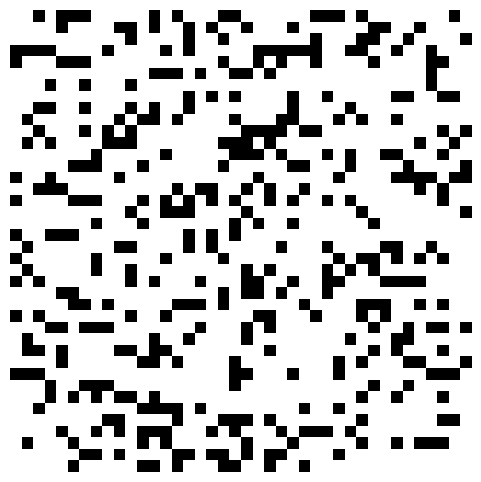

In [6]:
np.random.seed(1)
world=random_grid(40,40,0.25)
fig,ax=plt.subplots(figsize=(6,6)); ax.axis('off')
im=ax.imshow(world,cmap='binary')
def update(frame):
    global world
    world=step(world)
    im.set_data(world)
    return (im,)
ani=FuncAnimation(fig,update,frames=80,interval=120,blit=True)
plt.close()
HTML(ani.to_jshtml())

## 任务6：人口曲线（补全循环）

In [7]:
np.random.seed(2)
w=random_grid(40,40,0.3); pop=[]
for _ in range(150):
    # pop.append(???)   # 记录当前活细胞数
    # w = ???           # 演化一代
    pass
# plt.plot(pop); plt.xlabel('代数'); plt.ylabel('人口'); plt.show()


---
## 选做：Mandelbrot 分形

复平面每点 c，从 z=0 开始反复 `z=z^2+c`；一旦 |z|>2 视为逃逸，记录逃逸步数，最后成像。
**提示**：用 `xs[None,:]+1j*ys[:,None]` 广播出复数网格，用布尔数组记录"还没逃逸"的点。
（完整实现见参考答案末尾，先自己试。）

In [8]:
# 在此尝试


---
## 延伸挑战清单（国庆有空挑着玩）

1. 给生命游戏加"鼠标点击翻转细胞"的交互初始状态
2. 识别并统计振荡器（周期为2的图案）
3. NumPy 图像处理：读入照片做灰度、左右翻转、卷积模糊/边缘检测（用 PIL/Pillow 读图）
4. 用 NumPy 实现随机游走 / 蒙特卡洛估算 π
5. 生成 Julia 集（Mandelbrot 的近亲）

## 自查

- [ ] neighbors 在小网格上手算核对正确
- [ ] step 满足全部4条规则
- [ ] 滑翔机4代平移验证通过
- [ ] 动画能播放、人口曲线能画出
- [ ] 能向别人讲清楚"为什么用 roll 而不是双重for循环"（向量化思维）